# 01 — Refined Exploratory Data Analysis

**Project:** Egyptian Franco/Arabizi → Egyptian Arabic transliteration  
**Purpose:** produce trustworthy document-level descriptive statistics and a reproducible, non-destructive cleaned dataset. This notebook deliberately does **not** decide whether individual lines are parallel or suitable training pairs; that investigation belongs in the next alignment-validation notebook.

## Outputs

- `data/interim/dataset_refined.parquet` — typed dataset after explicitly documented invalid-row removal.
- `data/interim/doc_stats_refined.parquet` — corrected document-level features for later analysis and splitting.
- `reports/eda/` — summary tables, duplicate diagnostics, token-frequency diagnostics, and a JSON summary.
- `reports/figures/` — dataset-length and script/digit diagnostic plots.

## Important methodological rules

1. Preserve the original text. Any normalization in this notebook is used only to construct diagnostic keys, never to overwrite the model input or target.
2. Distinguish raw logical lines, non-empty lines, and blank lines.
3. Count whitespace-delimited tokens using `\S+`, not a literal space.
4. Report means, medians, and quantiles separately.
5. Do not infer semantic alignment from equal line counts.
6. Do not report an in-sample majority word mapping as model accuracy. Word-level mapping evaluation is deferred until after document-level splitting and alignment validation.
7. Do not normalize target spelling, Arabic letters, diacritics, or digit styles based on descriptive statistics alone.

## 1. Imports, reproducibility, and project paths

The notebook is designed to run with `notebooks/` or the repository root as the current working directory. It does not depend on the project package's text-processing module, so the feature definitions used here are visible and self-contained.

In [1]:
from __future__ import annotations

import collections
import json
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

SEED = 454
SAMPLE_SIZE = 30_000
TOKEN_SAMPLE_SIZE = 60_000

pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(120)

print("Polars version:", pl.__version__)
print("Current working directory:", Path.cwd())

cwd = Path.cwd().resolve()
candidate_roots = [cwd, cwd.parent, cwd.parent.parent]
PROJECT_ROOT = next(
    (root for root in candidate_roots if (root / "data" / "raw" / "dataset.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/raw/dataset.csv. Open this notebook from the repository "
        "root or notebooks/ directory, or edit DATASET_PATH in the next cell."
    )

DATASET_PATH = PROJECT_ROOT / "data" / "raw" / "dataset.csv"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
EDA_REPORT_DIR = PROJECT_ROOT / "reports" / "eda"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"

for directory in (INTERIM_DIR, EDA_REPORT_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

CLEAN_DATA_PATH = INTERIM_DIR / "dataset_refined.parquet"
DOC_STATS_PATH = INTERIM_DIR / "doc_stats_refined.parquet"

print("Project root:", PROJECT_ROOT)
print("Raw dataset:", DATASET_PATH)
print("Refined dataset output:", CLEAN_DATA_PATH)
print("Refined statistics output:", DOC_STATS_PATH)

Polars version: 2.1.0
Current working directory: /Users/ahmed/Desktop/PythonProjects/NLP/Project/arabizi-to-egyptian/notebooks
Project root: /Users/ahmed/Desktop/PythonProjects/NLP/Project/arabizi-to-egyptian
Raw dataset: /Users/ahmed/Desktop/PythonProjects/NLP/Project/arabizi-to-egyptian/data/raw/dataset.csv
Refined dataset output: /Users/ahmed/Desktop/PythonProjects/NLP/Project/arabizi-to-egyptian/data/interim/dataset_refined.parquet
Refined statistics output: /Users/ahmed/Desktop/PythonProjects/NLP/Project/arabizi-to-egyptian/data/interim/doc_stats_refined.parquet


## 2. Load the raw CSV and validate its schema

All columns are initially read as strings to avoid accidental inference in the text fields. The first header is normalized to `ID` to handle a possible UTF-8 BOM. The raw CSV is never modified.

In [3]:
t0 = time.time()
raw = pl.read_csv(
    DATASET_PATH,
    infer_schema_length=0,
    low_memory=True,
    try_parse_dates=False,
)

# Remove a possible UTF-8 BOM from the first column name.
first_column = raw.columns[0]
clean_first_column = first_column.lstrip("\ufeff")
if clean_first_column != first_column:
    raw = raw.rename({first_column: clean_first_column})

required_columns = {"ID", "Franco", "Egyptian"}
missing_columns = required_columns - set(raw.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}. Found: {raw.columns}")

# Cast IDs explicitly. Invalid IDs become null and are reported below.
raw = raw.with_columns(pl.col("ID").cast(pl.Int64, strict=False))

print(f"Loaded {raw.shape[0]:,} rows and {raw.shape[1]} columns in {time.time() - t0:.1f}s")
print("Null counts:")
display(raw.select([pl.col(c).null_count().alias(c) for c in raw.columns]))
print("Duplicate ID rows:", raw.height - raw.get_column("ID").n_unique())

Loaded 542,947 rows and 3 columns in 19.7s
Null counts:


ID,Franco,Egyptian
u32,u32,u32
0,11,1


Duplicate ID rows: 0


## 3. Document invalid rows and create a cleaned typed copy

Rows are excluded only when the ID or either side is null, or when either text side is empty/whitespace-only. The excluded rows are saved for audit. We do **not** exclude documents based on script composition, line counts, length ratios, or suspected alignment problems at this stage.

In [4]:
raw_row_count = raw.height
invalid_rows = raw.filter(
    pl.col("ID").is_null()
    | pl.col("Franco").is_null()
    | pl.col("Egyptian").is_null()
    | (pl.col("Franco").fill_null("").str.strip_chars() == "")
    | (pl.col("Egyptian").fill_null("").str.strip_chars() == "")
)

invalid_report_path = EDA_REPORT_DIR / "excluded_invalid_rows.csv"
invalid_row_count = invalid_rows.height
if invalid_row_count:
    invalid_rows.write_csv(invalid_report_path)
    print(f"Excluded {invalid_row_count:,} invalid rows; audit saved to {invalid_report_path}")
else:
    print("No invalid rows found.")

# Check ID integrity before saving. Duplicate IDs would make later joins unsafe.
valid = raw.filter(~pl.col("ID").is_null())
duplicate_id_rows = valid.height - valid.get_column("ID").n_unique()
if duplicate_id_rows:
    duplicates = valid.group_by("ID").len().filter(pl.col("len") > 1)
    duplicates.write_csv(EDA_REPORT_DIR / "duplicate_ids.csv")
    raise ValueError(
        f"Found {duplicate_id_rows:,} duplicate ID rows. Resolve them before continuing."
    )

df = raw.filter(
    pl.col("ID").is_not_null()
    & pl.col("Franco").is_not_null()
    & pl.col("Egyptian").is_not_null()
    & (pl.col("Franco").str.strip_chars() != "")
    & (pl.col("Egyptian").str.strip_chars() != "")
).select(
    pl.col("ID").cast(pl.Int64),
    pl.col("Franco").cast(pl.String),
    pl.col("Egyptian").cast(pl.String),
)

assert df.get_column("ID").n_unique() == df.height
assert df.select(
    (pl.col("Franco").str.strip_chars() == "").sum().alias("empty_franco"),
    (pl.col("Egyptian").str.strip_chars() == "").sum().alias("empty_egyptian"),
).row(0) == (0, 0)

df.write_parquet(CLEAN_DATA_PATH, compression="zstd")
print(f"Clean dataset: {df.height:,} rows -> {CLEAN_DATA_PATH}")
display(df.head(3))

# Release the multi-gigabyte raw frame; downstream analysis uses the cleaned copy.
del raw, invalid_rows, valid

Excluded 12 invalid rows; audit saved to /Users/ahmed/Desktop/PythonProjects/NLP/Project/arabizi-to-egyptian/reports/eda/excluded_invalid_rows.csv
Clean dataset: 542,935 rows -> /Users/ahmed/Desktop/PythonProjects/NLP/Project/arabizi-to-egyptian/data/interim/dataset_refined.parquet


ID,Franco,Egyptian
i64,str,str
1,"""n2l w t7weel el ta2a by7sl n2l el ta2a lma ta2a gsm bttn2l l gsm tany el 2anbela el nwya ta2a kymya le ta2a 7rarya 7rk e…","""نقل وتحويل الطاقة بيحصل نقل الطاقة لما طاقة جسم بتتنقل لجسم تاني القنبلة النووية طاقة كيميائية لطاقة حرارية حرق الخشب طا…"
2,"""- Entesal Elshabkeya - Tamazok Elshabkeya - E3telal Elshabkeya Elsukari - Eltaknos Elbaq3y Elmoratabit Bel3omr - Amrad E…","""ايه هو اعتلال الشبكية السكري الانتشاري؟ اعتلال الشبكية السكري هو مضاعفات لمرض السكري، وبيتميز بتلف تدريجي للشبكية. الحال…"
3,"""kayyas el-gowa el-dawaweya el-sakna wel-dawaweya el-mot7araka kayyas el-gowa el-dawaweya el-mot7araka byt3mel 3adaan be…","""قياس القوى الداورية الساكنة والداورية المتحركة قياس القوى الداورية المتحركة بيتعمل عادة باستخدام حساسات عزم الدوران على …"


## 5. Define robust, explicit feature-counting rules

- **Characters:** Polars `str.len_chars()` counts Unicode code points. This is not necessarily the same as user-perceived grapheme clusters.
- **Tokens/words:** count non-whitespace runs (`\S+`), so tabs and repeated spaces do not create fake tokens.
- **Logical lines:** Python `str.splitlines()` recognizes common line boundaries and does not create a phantom extra line solely because a document ends with a newline.
- **Non-empty lines:** logical lines containing at least one non-whitespace character.
- **Blank lines:** logical lines containing only whitespace.

We test the line-count helper on edge cases before applying it to the corpus.

In [21]:
def line_metrics(text: str) -> dict[str, int]:
    lines = text.splitlines()

    nonempty = sum(bool(line.strip()) for line in lines)
    blank = len(lines) - nonempty

    return {
        "logical_line_count": len(lines),
        "nonempty_line_count": nonempty,
        "blank_line_count": blank,
    }

test_texts = [
    "First line\nSecond line",
    "First line\n\nThird line",
    "First line\nSecond line\n",
    "Single line",
]

for text in test_texts:
    result = line_metrics(text)

    print(repr(text))
    print(result)

    assert result["logical_line_count"] == (
        result["nonempty_line_count"] + result["blank_line_count"]
    )

print("All logical-line edge-case checks passed.")

'First line\nSecond line'
{'logical_line_count': 2, 'nonempty_line_count': 2, 'blank_line_count': 0}
'First line\n\nThird line'
{'logical_line_count': 3, 'nonempty_line_count': 2, 'blank_line_count': 1}
'First line\nSecond line\n'
{'logical_line_count': 2, 'nonempty_line_count': 2, 'blank_line_count': 0}
'Single line'
{'logical_line_count': 1, 'nonempty_line_count': 1, 'blank_line_count': 0}
All logical-line edge-case checks passed.


## 6. Build corrected document-level statistics

The statistics include means, medians, and corrected whitespace-aware token counts. We store raw/logical line counts, non-empty line counts, and blank-line counts separately. No line pairs are constructed here.

For script composition, `f_arabic_letter_ratio` and `e_arabic_letter_ratio` are calculated among Unicode letters, not all characters. Script buckets are operational categories, not definitive language labels. This prevents spaces, digits, and punctuation from distorting script proportions. The Arabic-letter pattern is an explicit set of Arabic letter ranges; the Arabic diacritic/mark count is reported separately.

For every Franco–Egyptian pair, we calculate measurements that help us understand:
1. The length and size of documents.
2. The structural differences between source and target.
3. The script composition of each document.
4. The use of different digit systems and Arabic diacritics.
5. The distribution of document lengths.

In [22]:

# Explicit Arabic-script ranges. Arabic letters are kept separate from combining marks.
ARABIC_LETTER_PATTERN = (
    "[\u0620-\u063F\u0641-\u064A\u066E-\u066F"
    "\u0671-\u06D3\u06D5\u06EE-\u06EF\u06FA-\u06FC\u06FF"
    "\u0750-\u077F\u0870-\u0887\u08A0-\u08C9]"
)
ARABIC_MARK_PATTERN = "[\u064B-\u065F\u0670\u06D6-\u06ED]"
ARABIC_INDIC_DIGIT_PATTERN = r"[٠-٩]"
EXTENDED_ARABIC_INDIC_DIGIT_PATTERN = r"[۰-۹]"
WESTERN_DIGIT_PATTERN = r"[0-9]"
LATIN_ASCII_LETTER_PATTERN = r"[A-Za-z]"
ALL_UNICODE_LETTER_PATTERN = r"\p{L}"


def prefixed_line_metrics(text: str, prefix: str) -> dict[str, int]:
    metrics = line_metrics(text)
    return {f"{prefix}_{key}": value for key, value in metrics.items()}


F_LINE_DTYPE = pl.Struct([
    pl.Field("f_logical_line_count", pl.UInt32),
    pl.Field("f_nonempty_line_count", pl.UInt32),
    pl.Field("f_blank_line_count", pl.UInt32),
])

E_LINE_DTYPE = pl.Struct([
    pl.Field("e_logical_line_count", pl.UInt32),
    pl.Field("e_nonempty_line_count", pl.UInt32),
    pl.Field("e_blank_line_count", pl.UInt32),
])


stats = df.select(
    "ID",
    pl.col("Franco").str.len_chars().alias("f_chars"),
    pl.col("Egyptian").str.len_chars().alias("e_chars"),

    # Count non-whitespace runs, not literal spaces.
    pl.col("Franco").str.count_matches(r"\S+").alias("f_words"),
    pl.col("Egyptian").str.count_matches(r"\S+").alias("e_words"),

    # Logical, non-empty, and blank line counts.
    pl.col("Franco").map_elements(
        lambda x: prefixed_line_metrics(x, "f"),
        return_dtype=F_LINE_DTYPE,
    ).alias("_f"),

    pl.col("Egyptian").map_elements(
        lambda x: prefixed_line_metrics(x, "e"),
        return_dtype=E_LINE_DTYPE,
    ).alias("_e"),

    # Script and character counts.
    pl.col("Franco").str.count_matches(ARABIC_LETTER_PATTERN).alias("f_arabic_letters"),
    pl.col("Egyptian").str.count_matches(ARABIC_LETTER_PATTERN).alias("e_arabic_letters"),

    pl.col("Franco").str.count_matches(ALL_UNICODE_LETTER_PATTERN).alias("f_total_letters"),
    pl.col("Egyptian").str.count_matches(ALL_UNICODE_LETTER_PATTERN).alias("e_total_letters"),

    pl.col("Franco").str.count_matches(LATIN_ASCII_LETTER_PATTERN).alias("f_ascii_latin_letters"),
    pl.col("Egyptian").str.count_matches(LATIN_ASCII_LETTER_PATTERN).alias("e_ascii_latin_letters"),

    # Digit styles.
    pl.col("Franco").str.count_matches(ARABIC_INDIC_DIGIT_PATTERN).alias("f_indic_digits"),
    pl.col("Egyptian").str.count_matches(ARABIC_INDIC_DIGIT_PATTERN).alias("e_indic_digits"),

    pl.col("Franco").str.count_matches(EXTENDED_ARABIC_INDIC_DIGIT_PATTERN).alias("f_extended_indic_digits"),
    pl.col("Egyptian").str.count_matches(EXTENDED_ARABIC_INDIC_DIGIT_PATTERN).alias("e_extended_indic_digits"),

    pl.col("Franco").str.count_matches(WESTERN_DIGIT_PATTERN).alias("f_western_digits"),
    pl.col("Egyptian").str.count_matches(WESTERN_DIGIT_PATTERN).alias("e_western_digits"),

    # Arabic combining marks/diacritics.
    pl.col("Franco").str.count_matches(ARABIC_MARK_PATTERN).alias("f_arabic_marks"),
    pl.col("Egyptian").str.count_matches(ARABIC_MARK_PATTERN).alias("e_arabic_marks"),

).unnest(["_f", "_e"]).with_columns(

    # Script ratios use all Unicode letters as the denominator.
    pl.when(pl.col("f_total_letters") > 0)
      .then(pl.col("f_arabic_letters") / pl.col("f_total_letters"))
      .otherwise(None)
      .alias("f_arabic_letter_ratio"),

    pl.when(pl.col("e_total_letters") > 0)
      .then(pl.col("e_arabic_letters") / pl.col("e_total_letters"))
      .otherwise(None)
      .alias("e_arabic_letter_ratio"),

    pl.when(pl.col("f_total_letters") > 0)
      .then(pl.col("f_ascii_latin_letters") / pl.col("f_total_letters"))
      .otherwise(None)
      .alias("f_ascii_latin_letter_ratio"),

    pl.when(pl.col("e_total_letters") > 0)
      .then(pl.col("e_ascii_latin_letters") / pl.col("e_total_letters"))
      .otherwise(None)
      .alias("e_ascii_latin_letter_ratio"),

    # Target/source character-length ratio.
    pl.when(pl.col("f_chars") > 0)
      .then(pl.col("e_chars") / pl.col("f_chars"))
      .otherwise(None)
      .alias("char_ratio"),

    # Structural comparisons only; these do NOT establish alignment.
    (
        pl.col("f_nonempty_line_count")
        == pl.col("e_nonempty_line_count")
    ).alias("same_nonempty_line_count"),

    (
        pl.col("f_logical_line_count")
        == pl.col("e_logical_line_count")
    ).alias("same_logical_line_count"),

    (
        pl.col("e_logical_line_count").cast(pl.Int64)
        - pl.col("f_logical_line_count").cast(pl.Int64)
    ).alias("target_minus_source_logical_lines"),

    # Preserve the existing source-length buckets for comparability.
    pl.when(pl.col("f_chars") <= 700).then(pl.lit("xs"))
      .when(pl.col("f_chars") <= 1400).then(pl.lit("s"))
      .when(pl.col("f_chars") <= 2000).then(pl.lit("m"))
      .when(pl.col("f_chars") <= 3100).then(pl.lit("l"))
      .when(pl.col("f_chars") <= 4300).then(pl.lit("xl"))
      .otherwise(pl.lit("xxl"))
      .alias("len_bucket"),
)


# Operational Franco input categories.
# Latin-dominant currently means ASCII-Latin-dominant.
stats = stats.with_columns(
    pl.when(pl.col("f_total_letters") == 0)
      .then(pl.lit("No letters"))

      .when(
          (pl.col("f_arabic_letter_ratio") <= 0.05)
          & (pl.col("f_ascii_latin_letter_ratio") >= 0.50)
      )
      .then(pl.lit("Latin-dominant"))

      .when(pl.col("f_arabic_letter_ratio") <= 0.05)
      .then(pl.lit("Other low-Arabic"))

      .when(pl.col("f_arabic_letter_ratio") <= 0.50)
      .then(pl.lit("Mixed-script"))

      .otherwise(pl.lit("Arabic-dominant"))
      .alias("f_script_category")
)


# ---------------------------------------------------------
# Consistency checks
# ---------------------------------------------------------

assert stats.height == df.height
assert stats.get_column("ID").n_unique() == df.height

required_columns = {
    "f_words",
    "e_words",
    "f_logical_line_count",
    "e_logical_line_count",
    "f_nonempty_line_count",
    "e_nonempty_line_count",
    "f_blank_line_count",
    "e_blank_line_count",
    "f_script_category",
}

assert required_columns.issubset(stats.columns)

# Logical lines must equal non-empty lines plus blank lines.
assert stats.filter(
    pl.col("f_logical_line_count")
    != pl.col("f_nonempty_line_count") + pl.col("f_blank_line_count")
).height == 0

assert stats.filter(
    pl.col("e_logical_line_count")
    != pl.col("e_nonempty_line_count") + pl.col("e_blank_line_count")
).height == 0

# Validate whitespace-aware word counts against Python split().
word_check = df.sample(n=min(250, df.height), seed=SEED + 2).join(
    stats.select("ID", "f_words", "e_words"),
    on="ID",
    how="inner",
    validate="1:1",
)

for row in word_check.iter_rows(named=True):
    assert row["f_words"] == len(row["Franco"].split())
    assert row["e_words"] == len(row["Egyptian"].split())

# Validate the Arabic-letter and mark patterns.
assert re.findall(ARABIC_LETTER_PATTERN, "عربي 123 English") == list("عربي")
assert len(re.findall(ARABIC_MARK_PATTERN, "بِ")) == 1

# Script ratios must be between zero and one whenever defined.
for column in [
    "f_arabic_letter_ratio",
    "e_arabic_letter_ratio",
    "f_ascii_latin_letter_ratio",
    "e_ascii_latin_letter_ratio",
]:
    assert stats.filter(
        pl.col(column).is_not_null()
        & ((pl.col(column) < 0) | (pl.col(column) > 1))
    ).height == 0

print("Document-level statistics and consistency checks passed.")
display(stats.head())


Document-level statistics and consistency checks passed.


ID,f_chars,e_chars,f_words,e_words,f_logical_line_count,f_nonempty_line_count,f_blank_line_count,e_logical_line_count,e_nonempty_line_count,e_blank_line_count,f_arabic_letters,e_arabic_letters,f_total_letters,e_total_letters,f_ascii_latin_letters,e_ascii_latin_letters,f_indic_digits,e_indic_digits,f_extended_indic_digits,e_extended_indic_digits,f_western_digits,e_western_digits,f_arabic_marks,e_arabic_marks,f_arabic_letter_ratio,e_arabic_letter_ratio,f_ascii_latin_letter_ratio,e_ascii_latin_letter_ratio,char_ratio,same_nonempty_line_count,same_logical_line_count,target_minus_source_logical_lines,len_bucket,f_script_category
i64,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,f64,f64,f64,f64,f64,bool,bool,i64,str,str
1,432,407,86,65,11,11,0,11,11,0,0,340,309,340,309,0,0,0,0,0,33,0,0,0,0.0,1.0,1.0,0.0,0.94213,true,true,0,"""xs""","""Latin-dominant"""
2,583,1760,89,299,22,22,0,26,26,0,0,1389,455,1404,455,15,0,0,0,0,18,0,0,1,0.0,0.989316,1.0,0.010684,3.018868,false,false,4,"""xs""","""Latin-dominant"""
3,717,558,86,85,9,5,4,5,5,0,0,464,558,464,558,0,0,0,0,0,24,0,0,2,0.0,1.0,1.0,0.0,0.778243,true,false,-4,"""s""","""Latin-dominant"""
4,764,612,102,98,10,10,0,10,10,0,6,488,612,496,606,8,0,0,0,0,30,2,0,0,0.009804,0.983871,0.990196,0.016129,0.801047,true,true,0,"""s""","""Latin-dominant"""
5,1139,889,202,172,8,8,0,8,8,0,0,640,795,640,795,0,0,0,0,0,113,46,0,0,0.0,1.0,1.0,0.0,0.780509,true,true,0,"""s""","""Latin-dominant"""


In [23]:
assert stats.select(
    pl.col("f_logical_line_count").is_null().sum()
).item() == 0

assert stats.select(
    pl.col("e_logical_line_count").is_null().sum()
).item() == 0

assert (
    stats["f_logical_line_count"]
    == stats["f_nonempty_line_count"] + stats["f_blank_line_count"]
).all()

assert (
    stats["e_logical_line_count"]
    == stats["e_nonempty_line_count"] + stats["e_blank_line_count"]
).all()

print("Logical line-count validation passed.")

Logical line-count validation passed.


Key Findings:
1) Document length and token counts
2) Document line structure 
    - Logical lines - all lines
    - Non empty lines
    - Blank lines
3) Script composition
    - Latin-dominant
    - Other low-Arabic
    - Mixed-script
    - Arabic-dominant
    - No letters
4) Digit Systems and Arabic Marks
5) Document Length Buckets

| Finding | Implication for the project |
| --- | --- |
| Source and target lengths can differ substantially | Investigate unusual length ratios, but do not automatically discard examples. |
| Source and target line structures can differ. | Do not assume line-by-line alignment.| 
| The dataset may contain mixed-script and Arabic-dominant inputs. | Investigate script categories before deciding on training-data selection.| 
| Western digits appear in Franco text. | Preserve digits during initial preprocessing and investigate their linguistic roles.| 
| Arabic marks occur in the target. | Understand their frequency before deciding on normalization.| 
| Documents vary considerably in length. | Consider document length when designing batching, sequence limits, and model evaluation.| 

## 7. Summary statistics: mean, median, and quantiles

Means and medians are shown side by side. Quantiles are reported separately, so the notebook does not call a median or another quantile an average. Line metrics are explicitly named to show what is being counted.

In [25]:
metric_columns = [
    "f_chars", "e_chars",
    "f_words", "e_words",
    "f_logical_line_count", "e_logical_line_count",
    "f_nonempty_line_count", "e_nonempty_line_count",
    "f_blank_line_count", "e_blank_line_count",
    "char_ratio",
]

summary_rows = []
for column in metric_columns:
    series = stats.get_column(column).drop_nulls()
    summary_rows.append({
        "metric": column,
        "count": len(series),
        "mean": series.mean(),
        "median": series.median(),
        "std": series.std(),
        "min": series.min(),
        "max": series.max(),
    })

summary_stats = pl.DataFrame(summary_rows)
display(summary_stats)
summary_stats.write_csv(EDA_REPORT_DIR / "document_summary_statistics.csv")

QUANTILES = [0.0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999, 1.0]
quantile_rows = []
for q in QUANTILES:
    row = {"quantile": q}
    for column in metric_columns:
        row[column] = stats.get_column(column).quantile(q)
    quantile_rows.append(row)

quantile_table = pl.DataFrame(quantile_rows)
display(quantile_table)
quantile_table.write_csv(EDA_REPORT_DIR / "document_quantiles.csv")

metric,count,mean,median,std,min,max
str,i64,f64,f64,f64,f64,f64
"""f_chars""",542935,2310.06493,1993.0,1216.291727,4.0,6805.0
"""e_chars""",542935,1998.466211,1662.0,1163.552633,4.0,6770.0
"""f_words""",542935,368.294326,322.0,195.193246,1.0,1334.0
"""e_words""",542935,340.310534,288.0,194.281239,1.0,1382.0
"""f_logical_line_count""",542935,14.649938,13.0,10.687924,1.0,246.0
"""e_logical_line_count""",542935,13.204862,11.0,9.494428,1.0,191.0
"""f_nonempty_line_count""",542935,10.964572,8.0,8.430238,1.0,183.0
"""e_nonempty_line_count""",542935,11.333924,9.0,9.080674,1.0,185.0
"""f_blank_line_count""",542935,3.685366,2.0,4.908884,0.0,123.0


quantile,f_chars,e_chars,f_words,e_words,f_logical_line_count,e_logical_line_count,f_nonempty_line_count,e_nonempty_line_count,f_blank_line_count,e_blank_line_count,char_ratio
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.0,4.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.07489
0.01,395.0,341.0,62.0,58.0,1.0,1.0,1.0,1.0,0.0,0.0,0.75363
0.05,716.0,604.0,112.0,101.0,3.0,2.0,2.0,2.0,0.0,0.0,0.772113
0.25,1397.0,1169.0,225.0,203.0,8.0,7.0,6.0,6.0,0.0,0.0,0.799542
0.5,1993.0,1662.0,322.0,288.0,13.0,11.0,8.0,9.0,2.0,0.0,0.826037
0.75,3111.0,2595.0,490.0,439.0,18.0,17.0,14.0,14.0,6.0,4.0,0.878391
0.95,4658.0,4478.0,750.0,754.0,35.0,31.0,27.0,29.0,13.0,8.0,1.021099
0.99,5015.0,5286.0,879.0,887.0,54.0,48.0,42.0,46.0,21.0,14.0,1.20988
0.999,5326.0,5842.0,937.0,969.0,85.0,78.0,69.0,75.0,34.0,25.0,2.399351


| Finding |	Potential project implication | 
| --- | --- |
| Documents have variable lengths. | Use dynamic padding and length-aware batching. | 
| Target documents are generally shorter. | Do not assume equal source and target sequence lengths. | 
| Some documents have very high character ratios. | 	Investigate extreme pairs before deciding whether they are usable. | 
| Blank-line counts differ. | Avoid relying on source-target formatting alignment. | 
| Distributions are right-skewed. | Use medians and quantiles alongside means. | 

1) The dataset contains 542,935 complete document pairs for the analyzed metrics.

2) Egyptian target documents are generally shorter than Franco source documents.

3) Document lengths are highly variable and right-skewed.

4) Franco and Egyptian documents have different formatting characteristics, particularly regarding blank lines.

5) The character-ratio distribution contains extreme outliers that warrant further investigation.

## 8. Dataset size, duplicates, and normalized-input ambiguity

We distinguish exact duplicate pairs, repeated raw inputs, and repeated inputs after a conservative diagnostic normalization (lowercase plus whitespace collapse). The normalized key is used only for analysis; the original text is preserved. Punctuation, numerals, repeated letters, and Arabic spelling are not normalized away.

The diagnostic key does not perform Unicode NFC normalization. Canonically equivalent Unicode forms may therefore remain separate here; Unicode normalization will be evaluated explicitly in the later preprocessing stage, without changing the original stored text.

In [28]:
exact_duplicate_pair_rows = df.height - df.select("Franco", "Egyptian").unique().height
repeated_franco_raw_rows = df.height - df.get_column("Franco").n_unique()
repeated_egyptian_raw_rows = df.height - df.get_column("Egyptian").n_unique()

normalized_keys = df.select(
    pl.col("ID"),
    pl.col("Franco").str.to_lowercase().str.replace_all(r"\s+", " ").str.strip_chars().alias("_franco_key"),
    pl.col("Egyptian").str.to_lowercase().str.replace_all(r"\s+", " ").str.strip_chars().alias("_target_key"),
)

input_groups = (
    normalized_keys.group_by("_franco_key")
    .agg(
        pl.len().alias("rows"),
        pl.col("_target_key").n_unique().alias("unique_normalized_targets"),
    )
)
repeated_input_groups = input_groups.filter(pl.col("rows") > 1)
ambiguous_input_groups = repeated_input_groups.filter(pl.col("unique_normalized_targets") > 1)

ambiguous_key = "btetb3t 3ada fe khlal 5-15 yom"

ambiguous_ids = normalized_keys.filter(
    pl.col("_franco_key") == ambiguous_key
).select("ID")

display(
    df.join(ambiguous_ids, on="ID", how="inner")
      .select("ID", "Franco", "Egyptian")
)

del normalized_keys

print("Rows:", f"{df.height:,}")
print("Exact duplicate pair rows after first:", f"{exact_duplicate_pair_rows:,}")
print("Repeated raw Franco input rows after first:", f"{repeated_franco_raw_rows:,}")
print("Repeated raw Egyptian target rows after first:", f"{repeated_egyptian_raw_rows:,}")
print("Repeated normalized Franco input groups:", f"{repeated_input_groups.height:,}")
print("Normalized Franco inputs with multiple normalized targets:", f"{ambiguous_input_groups.height:,}")

repeated_input_groups.sort("rows", descending=True).write_csv(EDA_REPORT_DIR / "repeated_normalized_inputs.csv")
ambiguous_input_groups.sort("rows", descending=True).write_csv(EDA_REPORT_DIR / "ambiguous_normalized_inputs.csv")

ID,Franco,Egyptian
i64,str,str
162224,"""btetb3t 3ada fe khlal 5-15 yom""","""بتتبعت عادة في خلال ٥-١٥ يوم"""
291971,"""btetb3t 3ada fe khlal 5-15 yom""","""بتتبعت عادة في خلال 5-15 يوم"""


Rows: 542,935
Exact duplicate pair rows after first: 14
Repeated raw Franco input rows after first: 15
Repeated raw Egyptian target rows after first: 39
Repeated normalized Franco input groups: 11
Normalized Franco inputs with multiple normalized targets: 1


Key Implications:

1) Do not perform broad duplicate removal.
   - The exact duplicate count is negligible. We can decide later whether to remove exact duplicate pairs, but there is no need for aggressive deduplication.

2) Inspect the single ambiguous normalized input.
    - Both results revealed the same translation but a difference in the digits.

3) Group repeated normalized inputs when splitting the dataset.
    - We should ensure that all records belonging to the same normalized Franco input group are assigned to the same split.


| Finding | Conclusion | 
| --- | --- |
| 14 exact duplicate pair rows | Very few exact duplicates. | 
| 15 repeated raw Franco rows | Repeated inputs are uncommon. | 
| 39 repeated raw Egyptian rows | Repeated targets are also uncommon. | 
| 11 repeated normalized Franco groups | 	Some inputs differ only in case or whitespace. | 
| 1 normalized input with multiple targets | Explained by Western versus Arabic-Indic digit formatting. | 


## 9. Script composition, digits, and Arabic marks

The script ratios use **letter characters** as the denominator. Arabic letters are counted separately from Arabic diacritics/marks, punctuation, digits, and spaces. We also measure source and target digit styles side by side. The results are descriptive: they do not justify forcing Western digits or normalizing the target.

In [29]:
script_summary = pl.DataFrame([
    {
        "property": "Franco contains Arabic letters",
        "documents": stats.filter(pl.col("f_arabic_letters") > 0).height,
    },
    {
        "property": "Franco is more than 50% Arabic letters among letters",
        "documents": stats.filter(pl.col("f_arabic_letter_ratio") > 0.5).height,
    },
    {
        "property": "Egyptian contains Arabic letters",
        "documents": stats.filter(pl.col("e_arabic_letters") > 0).height,
    },
    {
        "property": "Egyptian contains ASCII Latin letters",
        "documents": stats.filter(pl.col("e_ascii_latin_letters") > 0).height,
    },
    {
        "property": "Franco contains Arabic-Indic digits",
        "documents": stats.filter(pl.col("f_indic_digits") > 0).height,
    },
    {
        "property": "Egyptian contains Arabic-Indic digits",
        "documents": stats.filter(pl.col("e_indic_digits") > 0).height,
    },
    {
        "property": "Egyptian contains extended Arabic-Indic digits",
        "documents": stats.filter(pl.col("e_extended_indic_digits") > 0).height,
    },
    {
        "property": "Egyptian contains Western digits",
        "documents": stats.filter(pl.col("e_western_digits") > 0).height,
    },
    {
        "property": "Egyptian contains Arabic marks/diacritics",
        "documents": stats.filter(pl.col("e_arabic_marks") > 0).height,
    },
]).with_columns((pl.col("documents") / df.height * 100).round(2).alias("percent"))

display(script_summary)
script_summary.write_csv(EDA_REPORT_DIR / "script_and_digit_summary.csv")

script_category_summary = (
    stats.group_by("f_script_category")
    .agg(pl.len().alias("documents"))
    .with_columns((pl.col("documents") / stats.height * 100).round(2).alias("percent"))
    .sort("f_script_category")
)
display(script_category_summary)
script_category_summary.write_csv(EDA_REPORT_DIR / "franco_script_category_summary.csv")

letter_totals = stats.select(
    pl.col("f_total_letters").sum().alias("franco_total_letters"),
    pl.col("e_total_letters").sum().alias("egyptian_total_letters"),
    pl.col("f_arabic_letters").sum().alias("franco_arabic_letters"),
    pl.col("e_arabic_letters").sum().alias("egyptian_arabic_letters"),
    pl.col("e_arabic_marks").sum().alias("egyptian_arabic_marks"),
    pl.col("e_indic_digits").sum().alias("egyptian_arabic_indic_digits"),
    pl.col("e_extended_indic_digits").sum().alias("egyptian_extended_indic_digits"),
    pl.col("e_western_digits").sum().alias("egyptian_western_digits"),
)
display(letter_totals)

property,documents,percent
str,i64,f64
"""Franco contains Arabic letters""",89152,16.42
"""Franco is more than 50% Arabic letters among letters""",18327,3.38
"""Egyptian contains Arabic letters""",542927,100.0
"""Egyptian contains ASCII Latin letters""",179169,33.0
"""Franco contains Arabic-Indic digits""",4844,0.89
"""Egyptian contains Arabic-Indic digits""",64216,11.83
"""Egyptian contains extended Arabic-Indic digits""",13,0.0
"""Egyptian contains Western digits""",361620,66.6
"""Egyptian contains Arabic marks/diacritics""",452166,83.28


f_script_category,documents,percent
str,u32,f64
"""Arabic-dominant""",18327,3.38
"""Latin-dominant""",523624,96.44
"""Mixed-script""",973,0.18
"""No letters""",8,0.0
"""Other low-Arabic""",3,0.0


franco_total_letters,egyptian_total_letters,franco_arabic_letters,egyptian_arabic_letters,egyptian_arabic_marks,egyptian_arabic_indic_digits,egyptian_extended_indic_digits,egyptian_western_digits
u32,u32,u32,u32,u32,u32,u32,u32
934440630,856987102,33522756,848448218,2533696,860732,58,7887279


Key Findings:

| Finding |	Project implication | 
| --- | --- |
| 96.44% of sources are Latin-dominant. | 	The dataset is broadly suitable for the intended transliteration task. | 
| 16.42% of sources contain Arabic letters. | 	Do not automatically remove every mixed-character source. | 
| 3.38% are Arabic-dominant. |  Investigate these separately before deciding their training role. | 
| 33% of targets contain Latin letters. | 	The output vocabulary must support code-switching and Latin characters. | 
| Targets use multiple digit systems. |  Avoid digit normalization until we understand the conventions. | 
| 83.28% of targets contain Arabic marks. | Diacritic handling may significantly affect model output and CER. | 

### 9.1 Inspect digit-style relationships without imposing a normalization rule

This cross-tab compares the presence of digit styles in the source and target at document level. Presence does not mean every numeral in a document follows that style; a document may contain more than one digit system.

In [30]:
digit_profiles = stats.with_columns(
    pl.when((pl.col("f_western_digits") > 0) & ((pl.col("f_indic_digits") + pl.col("f_extended_indic_digits")) > 0)).then(pl.lit("Western + Indic"))
      .when(pl.col("f_western_digits") > 0).then(pl.lit("Western only"))
      .when((pl.col("f_indic_digits") + pl.col("f_extended_indic_digits")) > 0).then(pl.lit("Indic only"))
      .otherwise(pl.lit("No counted digits")).alias("source_digit_profile"),
    pl.when((pl.col("e_western_digits") > 0) & ((pl.col("e_indic_digits") + pl.col("e_extended_indic_digits")) > 0)).then(pl.lit("Western + Indic"))
      .when(pl.col("e_western_digits") > 0).then(pl.lit("Western only"))
      .when((pl.col("e_indic_digits") + pl.col("e_extended_indic_digits")) > 0).then(pl.lit("Indic only"))
      .otherwise(pl.lit("No counted digits")).alias("target_digit_profile"),
)
digit_crosstab = (
    digit_profiles.group_by("source_digit_profile", "target_digit_profile")
    .len().sort("source_digit_profile", "target_digit_profile")
)
display(digit_crosstab)
digit_crosstab.write_csv(EDA_REPORT_DIR / "source_target_digit_profiles.csv")

source_digit_profile,target_digit_profile,len
str,str,u32
"""Indic only""","""Indic only""",1599
"""Indic only""","""No counted digits""",44
"""Indic only""","""Western + Indic""",46
"""Indic only""","""Western only""",1339
"""No counted digits""","""Indic only""",3
"""No counted digits""","""No counted digits""",1768
"""No counted digits""","""Western + Indic""",1
"""No counted digits""","""Western only""",39
"""Western + Indic""","""Indic only""",1099


Key Findings:

1. Franco documents overwhelmingly use Western digits.
2. Egyptian targets exhibit considerably more variation in digit styles.
3. Western digits are frequently retained, but some are represented using Arabic-Indic digits in the target.
4. Some target documents contain no counted digits despite their sources containing them.
5. Digit-style conversion is not entirely consistent across the dataset.

## 10. Character inventory (deterministic document sample)

This section measures the observed character inventory on a reproducible sample. It does not conclude that rare characters should be removed: the model vocabulary/copy strategy will be decided during feature engineering.

In [31]:
sample_n = min(SAMPLE_SIZE, df.height)
char_sample = df.sample(n=sample_n, seed=SEED)
character_inventory = {}

for column in ("Franco", "Egyptian"):
    counts = collections.Counter()
    for text in char_sample.get_column(column):
        counts.update(text)
    character_inventory[column] = counts
    total = sum(counts.values())
    sorted_counts = sorted(counts.values(), reverse=True)
    cumulative = np.cumsum(sorted_counts) / total if total else np.array([])
    top100_coverage = float(cumulative[min(99, len(cumulative)-1)]) if len(cumulative) else 0.0
    top200_coverage = float(cumulative[min(199, len(cumulative)-1)]) if len(cumulative) else 0.0
    print(f"{column}: {len(counts):,} distinct code points in {sample_n:,} documents")
    print(f"  top-100 coverage: {top100_coverage * 100:.4f}%")
    print(f"  top-200 coverage: {top200_coverage * 100:.4f}%")
    print("  most frequent 60:", " ".join(repr(ch) for ch, _ in counts.most_common(60)))

    frequency_df = pl.DataFrame(
        {"character": [ch for ch, _ in counts.most_common()],
         "count": [n for _, n in counts.most_common()]}
    )
    frequency_df.head(500).write_csv(EDA_REPORT_DIR / f"{column.lower()}_character_frequency_sample.csv")

del char_sample

Franco: 1,003 distinct code points in 30,000 documents
  top-100 coverage: 99.8289%
  top-200 coverage: 99.9947%
  most frequent 60: ' ' 'a' 'e' 'l' 't' 'm' 'n' 'o' 's' 'y' 'h' 'r' 'b' 'd' '3' 'w' 'k' 'f' '2' '7' '-' 'g' '.' ',' 'i' 'z' '\n' "'" 'ا' '5' 'ل' 'q' 'ي' 'j' 'u' 'E' 'م' 'و' '"' 'ن' '0' 'ت' '1' 'ر' '6' 'c' 'ب' 'A' 'M' 'د' ':' 'ع' 'p' 'ة' '9' 'س' ')' 'B' '(' 'ف'
Egyptian: 1,285 distinct code points in 30,000 documents
  top-100 coverage: 99.7953%
  top-200 coverage: 99.9923%
  most frequent 60: ' ' 'ا' 'ل' 'ي' 'م' 'و' 'ن' 'ت' 'ر' 'ب' 'ع' 'ة' 'د' 'ك' 'ف' 'س' 'ه' 'ق' 'ح' 'أ' 'ج' '.' '،' 'ش' 'ط' 'ص' 'خ' '\n' 'ز' 'إ' 'ى' 'ض' 'غ' 'ث' 'ئ' 'ء' 'ذ' '"' 'ً' 'ظ' '-' '0' '1' '2' ':' ')' '(' 'e' 'ؤ' '؟' '5' 'آ' '9' '3' 'a' '4' '8' 't' 'o' 'i'


Key findings:

1. The 30,000-document sample contains 1,003 distinct Franco code points and 1,285 Egyptian code points.

2. Character frequencies are highly concentrated: the top 100 characters account for more than 99.79% of occurrences in both representations.

3. Franco contains common Arabizi digits as well as Arabic-script characters.

4. Egyptian is dominated by Arabic letters but also includes diacritics, Latin characters, digits, and punctuation.

5. A long tail of uncommon Unicode characters exists, including emojis, foreign scripts, and special symbols.
   
6. Build separate source and target vocabularies.
   

## 11. Whitespace-token frequency and type imbalance (source-side diagnostic only)

We inspect the frequency distribution of whitespace-delimited Franco tokens in a deterministic sample of Latin-dominant documents. This quantifies the long-tail frequency problem without constructing a Franco→Egyptian word mapping from unverified positional pairs.

**No mapping accuracy is reported here.** A valid majority-word baseline requires (a) validated source-target alignment, (b) a document-level train/development split, and (c) mapping construction using training data only.

In [32]:
latin_dominant_sample_pool = df.join(
    stats.select("ID", "f_script_category"), on="ID", how="inner"
).filter(pl.col("f_script_category") == "Latin-dominant")

token_sample_n = min(TOKEN_SAMPLE_SIZE, latin_dominant_sample_pool.height)
token_sample = latin_dominant_sample_pool.sample(n=token_sample_n, seed=SEED + 1)
source_token_counts = collections.Counter()
for text in token_sample.get_column("Franco"):
    source_token_counts.update(token.lower() for token in re.findall(r"\S+", text))

frequency_values = list(source_token_counts.values())
token_total = sum(frequency_values)
type_count = len(source_token_counts)

frequency_bands = [
    ("1", lambda n: n == 1),
    ("2–5", lambda n: 2 <= n <= 5),
    ("6–20", lambda n: 6 <= n <= 20),
    ("21–100", lambda n: 21 <= n <= 100),
    ("101–1000", lambda n: 101 <= n <= 1000),
    (">1000", lambda n: n > 1000),
]
band_rows = []
for label, predicate in frequency_bands:
    types_in_band = sum(predicate(n) for n in frequency_values)
    tokens_in_band = sum(n for n in frequency_values if predicate(n))
    band_rows.append({
        "occurrence_frequency": label,
        "word_types": types_in_band,
        "word_type_percent": (types_in_band / type_count * 100) if type_count else 0,
        "token_occurrences": tokens_in_band,
        "token_percent": (tokens_in_band / token_total * 100) if token_total else 0,
    })

source_token_frequency_bands = pl.DataFrame(band_rows)
print(f"Documents sampled: {token_sample_n:,}")
print(f"Whitespace token occurrences: {token_total:,}")
print(f"Distinct lowercased source token types: {type_count:,}")
display(source_token_frequency_bands)
display(pl.DataFrame({
    "token": [x for x, _ in source_token_counts.most_common(50)],
    "count": [n for _, n in source_token_counts.most_common(50)],
}))
source_token_frequency_bands.write_csv(EDA_REPORT_DIR / "source_token_frequency_bands.csv")
pl.DataFrame({
    "token": [x for x, _ in source_token_counts.most_common()],
    "count": [n for _, n in source_token_counts.most_common()],
}).head(10_000).write_csv(EDA_REPORT_DIR / "source_token_frequencies_sample.csv")
del token_sample, latin_dominant_sample_pool

Documents sampled: 60,000
Whitespace token occurrences: 22,075,977
Distinct lowercased source token types: 2,212,774


occurrence_frequency,word_types,word_type_percent,token_occurrences,token_percent
str,i64,f64,i64,f64
"""1""",1400581,63.295257,1400581,6.344367
"""2–5""",558165,25.224673,1547607,7.010367
"""6–20""",176557,7.978989,1781830,8.071353
"""21–100""",60253,2.722962,2517251,11.402671
"""101–1000""",15704,0.709697,4008654,18.158444
""">1000""",1514,0.068421,10820054,49.012798


token,count
str,i64
"""el""",1465819
"""w""",791448
"""fe""",593090
"""men""",276475
"""elly""",257371
"""mn""",174295
"""en""",173409
"""3ala""",158474
"""-""",153176


Key Findings:

1. The 60,000-document sample contains 22.08 million token occurrences and 2.21 million distinct lowercased token types.

2. Approximately 63.30% of token types occur exactly once.

3. Approximately 88.52% occur no more than five times.

4. Only 0.068% of token types occur more than 1,000 times, but they account for 49.01% of all token occurrences.

5. Common Franco spellings and their variants demonstrate the non-standardized nature of the source language.

## 12. Document-level line structure — no positional pairing

We summarize how many documents have equal versus different non-empty line counts. This is a **structural diagnostic only**. Equal counts do not prove semantic correspondence, and unequal counts do not prove truncation. The next notebook will inspect correspondence, missing content, formatting differences, and possible segmentation strategies.

In [34]:
line_structure_summary = pl.DataFrame([
    {"measurement": "Same non-empty line count", "documents": stats.filter(pl.col("same_nonempty_line_count")).height},
    {"measurement": "Different non-empty line counts", "documents": stats.filter(~pl.col("same_nonempty_line_count")).height},
    {"measurement": "Same raw logical line count", "documents": stats.filter(pl.col("same_logical_line_count")).height},
    {"measurement": "Different raw logical line counts", "documents": stats.filter(~pl.col("same_logical_line_count")).height},
    {"measurement": "Source contains at least one blank line", "documents": stats.filter(pl.col("f_blank_line_count") > 0).height},
    {"measurement": "Target contains at least one blank line", "documents": stats.filter(pl.col("e_blank_line_count") > 0).height},
]).with_columns((pl.col("documents") / stats.height * 100).round(2).alias("percent"))

display(line_structure_summary)
line_structure_summary.write_csv(EDA_REPORT_DIR / "line_structure_summary.csv")

display(
    stats.group_by("len_bucket")
    .agg(
        pl.len().alias("documents"),
        pl.col("f_nonempty_line_count").mean().alias("mean_source_nonempty_lines"),
        pl.col("e_nonempty_line_count").mean().alias("mean_target_nonempty_lines"),
        pl.col("same_nonempty_line_count").mean().alias("same_nonempty_line_count_rate"),
    )
    .sort("len_bucket")
)

measurement,documents,percent
str,i64,f64
"""Same non-empty line count""",480255,88.46
"""Different non-empty line counts""",62680,11.54
"""Same raw logical line count""",375496,69.16
"""Different raw logical line counts""",167439,30.84
"""Source contains at least one blank line""",286370,52.74
"""Target contains at least one blank line""",158789,29.25


len_bucket,documents,mean_source_nonempty_lines,mean_target_nonempty_lines,same_nonempty_line_count_rate
str,u32,f64,f64,f64
"""l""",133446,11.500847,11.514965,0.958328
"""m""",136497,8.406456,8.429621,0.969289
"""s""",110812,6.261461,6.307187,0.956801
"""xl""",79939,16.877544,17.319869,0.860168
"""xs""",25640,4.060218,4.224961,0.913066
"""xxl""",56601,19.853518,22.518454,0.386354


Key Findings:

1. 88.46% of all document pairs have the same number of non-empty lines.

2. Only 69.16% have the same total logical line count.

3. Blank lines are considerably more common in Franco than in Egyptian documents.

4. Structural agreement remains high for XS through L documents.

5. Agreement decreases for XL documents and drops sharply to 38.64% for XXL documents.

6. XXL targets contain more non-empty lines on average than their Franco sources.

## 13. Visual summaries

The histograms are clipped at selected high quantiles for readability; the underlying full distributions remain available in the CSV summary tables. Raw and non-empty line counts are shown separately.

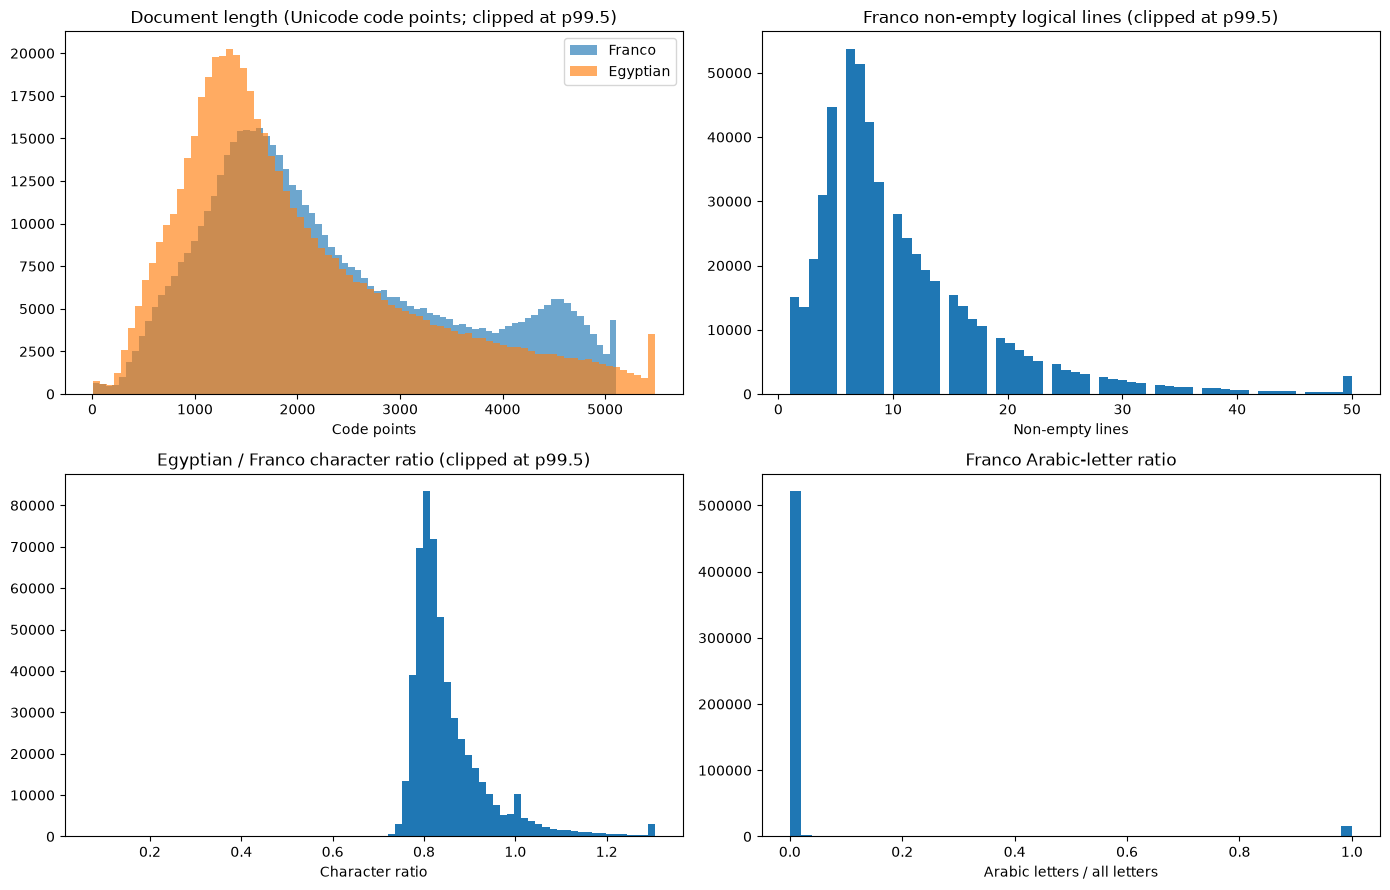

In [35]:
f_char_p995 = stats.get_column("f_chars").quantile(0.995)
e_char_p995 = stats.get_column("e_chars").quantile(0.995)
f_lines_p995 = stats.get_column("f_nonempty_line_count").quantile(0.995)
ratio_p995 = stats.get_column("char_ratio").drop_nulls().quantile(0.995)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].hist(stats.get_column("f_chars").clip(upper_bound=f_char_p995), bins=80, alpha=0.65, label="Franco")
axes[0, 0].hist(stats.get_column("e_chars").clip(upper_bound=e_char_p995), bins=80, alpha=0.65, label="Egyptian")
axes[0, 0].set(title="Document length (Unicode code points; clipped at p99.5)", xlabel="Code points")
axes[0, 0].legend()

axes[0, 1].hist(stats.get_column("f_nonempty_line_count").clip(upper_bound=f_lines_p995), bins=60)
axes[0, 1].set(title="Franco non-empty logical lines (clipped at p99.5)", xlabel="Non-empty lines")

axes[1, 0].hist(stats.get_column("char_ratio").drop_nulls().clip(0, ratio_p995), bins=80)
axes[1, 0].set(title="Egyptian / Franco character ratio (clipped at p99.5)", xlabel="Character ratio")

axes[1, 1].hist(stats.get_column("f_arabic_letter_ratio").drop_nulls(), bins=50)
axes[1, 1].set(title="Franco Arabic-letter ratio", xlabel="Arabic letters / all letters")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_refined_document_statistics.png", dpi=140, bbox_inches="tight")
plt.show()

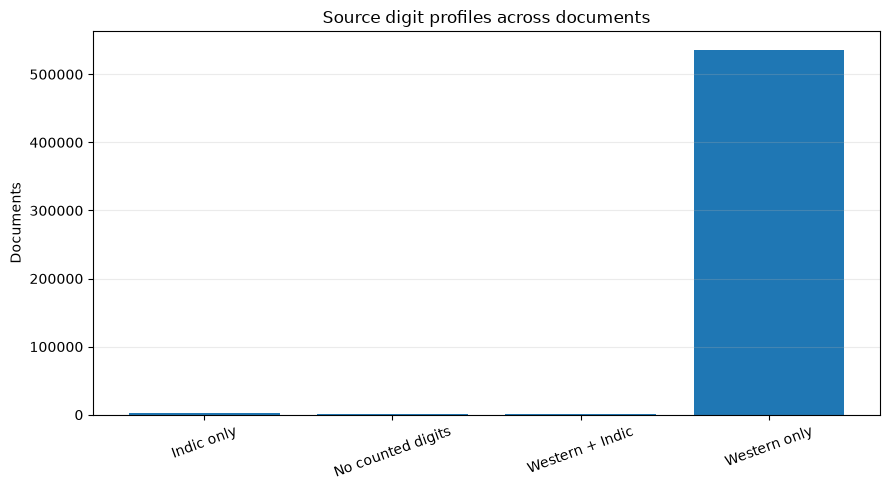

In [36]:
fig, ax = plt.subplots(figsize=(9, 5))
profile_counts = digit_crosstab.group_by("source_digit_profile").agg(pl.col("len").sum().alias("documents"))
ax.bar(profile_counts.get_column("source_digit_profile").to_list(), profile_counts.get_column("documents").to_list())
ax.set_title("Source digit profiles across documents")
ax.set_ylabel("Documents")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_refined_digit_profiles.png", dpi=140, bbox_inches="tight")
plt.show()

| Observation |	Implication |
| --- | --- |
| Document lengths are right-skewed |	Account for long documents when selecting sequence-length limits. |
| Franco documents have a long tail of line counts |	Do not assume a uniform document structure. |
| Egyptian targets are generally shorter |	The model needs variable-length decoding. |
| Most source documents are Latin-dominant | Franco-to-Egyptian transliteration is the primary task. |
| Some source documents contain Arabic script |	Preserve and investigate mixed-script cases. |
| Franco overwhelmingly uses Western digits |	Preserve digits and distinguish numerical values from Arabizi phonetic symbols. |

## 14. Save refined document statistics and a machine-readable summary

The refined statistics file intentionally uses explicit names (`f_nonempty_line_count`, not the ambiguous `f_lines`; `same_nonempty_line_count`, not `aligned`). The next alignment-validation notebook should consume this schema and must not interpret the line-count flag as semantic alignment.

In [38]:
# Preserve only document-level features; original text remains in dataset_refined.parquet.
doc_stats = stats.select(
    "ID",
    "f_chars", "e_chars", "f_words", "e_words",
    "f_logical_line_count", "e_logical_line_count",
    "f_nonempty_line_count", "e_nonempty_line_count",
    "f_blank_line_count", "e_blank_line_count",
    "f_arabic_letters", "e_arabic_letters",
    "f_total_letters", "e_total_letters",
    "f_ascii_latin_letters", "e_ascii_latin_letters",
    "f_arabic_letter_ratio", "e_arabic_letter_ratio",
    "f_script_category",
    "f_ascii_latin_letter_ratio", "e_ascii_latin_letter_ratio",
    "f_indic_digits", "e_indic_digits",
    "f_extended_indic_digits", "e_extended_indic_digits",
    "f_western_digits", "e_western_digits",
    "f_arabic_marks", "e_arabic_marks",
    "char_ratio", "same_nonempty_line_count", "same_logical_line_count",
    "target_minus_source_logical_lines", "len_bucket",
)

doc_stats.write_parquet(DOC_STATS_PATH, compression="zstd")
print(f"Saved {doc_stats.height:,} document-statistics rows -> {DOC_STATS_PATH}")
print("Statistics schema:")
print(doc_stats.schema)

Saved 542,935 document-statistics rows -> /Users/ahmed/Desktop/PythonProjects/NLP/Project/arabizi-to-egyptian/data/interim/doc_stats_refined.parquet
Statistics schema:
Schema([('ID', Int64), ('f_chars', UInt32), ('e_chars', UInt32), ('f_words', UInt32), ('e_words', UInt32), ('f_logical_line_count', UInt32), ('e_logical_line_count', UInt32), ('f_nonempty_line_count', UInt32), ('e_nonempty_line_count', UInt32), ('f_blank_line_count', UInt32), ('e_blank_line_count', UInt32), ('f_arabic_letters', UInt32), ('e_arabic_letters', UInt32), ('f_total_letters', UInt32), ('e_total_letters', UInt32), ('f_ascii_latin_letters', UInt32), ('e_ascii_latin_letters', UInt32), ('f_arabic_letter_ratio', Float64), ('e_arabic_letter_ratio', Float64), ('f_script_category', String), ('f_ascii_latin_letter_ratio', Float64), ('e_ascii_latin_letter_ratio', Float64), ('f_indic_digits', UInt32), ('e_indic_digits', UInt32), ('f_extended_indic_digits', UInt32), ('e_extended_indic_digits', UInt32), ('f_western_digits',

In [39]:
summary = {
    "dataset_rows_raw": raw_row_count,
    "dataset_rows_retained": df.height,
    "rows_excluded": invalid_row_count,
    "unique_ids_retained": df.get_column("ID").n_unique(),
    "exact_duplicate_pair_rows_after_first": exact_duplicate_pair_rows,
    "repeated_raw_franco_rows_after_first": repeated_franco_raw_rows,
    "repeated_normalized_franco_groups": repeated_input_groups.height,
    "ambiguous_normalized_franco_groups": ambiguous_input_groups.height,
    "same_nonempty_line_count_documents": stats.filter(pl.col("same_nonempty_line_count")).height,
    "different_nonempty_line_count_documents": stats.filter(~pl.col("same_nonempty_line_count")).height,
    "outputs": {
        "clean_dataset": str(CLEAN_DATA_PATH),
        "document_statistics": str(DOC_STATS_PATH),
        "reports_directory": str(EDA_REPORT_DIR),
        "figures_directory": str(FIGURE_DIR),
    },
    "methodological_notes": [
        "Original text was retained; diagnostic normalized keys were not written back to the dataset.",
        "Word counts use non-whitespace runs (\\S+).",
        "Logical line counts use Python str.splitlines(); blank and non-empty lines are separate.",
        "Character lengths count Unicode code points, not grapheme clusters.",
        "Script ratios use Arabic-letter counts divided by all Unicode-letter counts.",
        "No line-level positional pairs or word-mapping accuracy were computed.",
        "Equal non-empty line counts are not proof of semantic alignment.",
        "No digit, hamza, ta marbuta, ya, or diacritic normalization was applied.",
    ],
}
(EDA_REPORT_DIR / "eda_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(json.dumps(summary, ensure_ascii=False, indent=2))

{
  "dataset_rows_raw": 542947,
  "dataset_rows_retained": 542935,
  "rows_excluded": 12,
  "unique_ids_retained": 542935,
  "exact_duplicate_pair_rows_after_first": 14,
  "repeated_raw_franco_rows_after_first": 15,
  "repeated_normalized_franco_groups": 11,
  "ambiguous_normalized_franco_groups": 1,
  "same_nonempty_line_count_documents": 480255,
  "different_nonempty_line_count_documents": 62680,
  "outputs": {
    "clean_dataset": "/Users/ahmed/Desktop/PythonProjects/NLP/Project/arabizi-to-egyptian/data/interim/dataset_refined.parquet",
    "document_statistics": "/Users/ahmed/Desktop/PythonProjects/NLP/Project/arabizi-to-egyptian/data/interim/doc_stats_refined.parquet",
    "reports_directory": "/Users/ahmed/Desktop/PythonProjects/NLP/Project/arabizi-to-egyptian/reports/eda",
    "figures_directory": "/Users/ahmed/Desktop/PythonProjects/NLP/Project/arabizi-to-egyptian/reports/figures"
  },
  "methodological_notes": [
    "Original text was retained; diagnostic normalized keys were 

## 15. Interpretation checklist and handoff to alignment validation

Before proceeding, record the following conclusions in the project report:

- Are means and medians materially different for document lengths and token counts?
  - The distributions are right-skewed, particularly for document lengths and token counts.
- How large is the whitespace-only/invalid-row exclusion, and are those rows saved for audit?
  - The original dataset contained 12 rows with missing values: 11 rows had a missing Franco value. and 1 row had a missing Egyptian value.
- How different are raw logical-line counts from non-empty-line counts?
  - There is a meaningful difference because blank lines are common, especially in Franco documents.
- How many repeated normalized Franco inputs have multiple target variants?
  - Only one normalized Franco input group had multiple normalized target variants.
  - The two records differed only in the representation of digits in the Egyptian target:
    - One used Arabic-Indic digits.
    - The other used Western digits.
- How long is the character long tail, and what characters must the tokenizer support?
    - The tokenizer should support the full set of valid characters observed in the training data, not only the most frequent 100 or 200. We should preserve Unicode and investigate unusual characters rather than silently discard them.
- What does the source/target digit-style cross-tab show? Do **not** impose a digit conversion rule based only on document-level presence.
  - Digit conventions vary between source and target. More importantly, Franco digits can encode Arabic phonemes, not just numerical values. Therefore, we must not impose a global digit-conversion rule based on document-level presence.


### Explicitly deferred to `02_alignment_validation`

1. Manually verify whether corresponding lines are semantically parallel.
2. Inspect documents with equal line counts as well as mismatched counts.
3. Investigate missing content, paragraph restructuring, formatting differences, and truncation hypotheses.
4. Test any proposed alignment or segmentation algorithm against manually reviewed examples.
5. Estimate what proportion of the corpus can safely become training pairs.

### Decisions not made by this notebook

This notebook does **not** decide which script categories to train on, whether to keep Arabic-dominant inputs, whether to drop long documents, whether to normalize target orthography/digits, or whether to use line-level or sentence-level training examples. Those decisions require alignment evidence and a later document-level train/development split.